# P4.04 — How much do random splits flatter a price forecast?

**Question:** M5 (how reliable are price forecasts under rolling time-based validation versus random splits?).
The project validates every forecast on rolling origins (`p4_01`, `p4_03`). This notebook shows what that rule
buys, by scoring *one* model four ways on the same targets.

**Test case.** A least-squares regression of the h-quarter change in a log series on its last four quarterly
changes (`forecasting.direct_design`). It is deliberately plain: the point is the validation scheme, not the
model, and it is not the project's forecaster (ETS is). Series as in `p4_01`: national real house price index and
ownership cost index, 2009Q1 to 2026Q2. Horizons 1, 4 and 8 quarters.

**Schemes** (`forecasting.validation_schemes`), all scored on the rows a rolling origin can score (origins from
2017Q4):
1. **rolling origin** — train on what was known at the origin. The real-time answer.
2. **random folds** — five shuffled folds, the default of most toolkits; 20 repeats. Trains on the future and on
   rows whose windows overlap the test row.
3. **leave one out, purged** — train on everything more than h + 4 quarters away, either side. Uses the future but
   no overlapping window.
4. **blocks, purged** — five contiguous blocks, the edges purged. Also uses the future, no overlap.

**Reading rule, fixed before looking:** a scheme overstates skill if its skill (1 minus the RMSE ratio to a
no-change forecast) exceeds the rolling-origin skill by more than the spread across the random repeats.

In [1]:
import numpy as np
import pandas as pd

from pthousing.analysis import forecasting as fc
from pthousing.config import BASE_YEAR
from pthousing.data import build_panel
from pthousing.features import affordability as aff
from pthousing.viz import charts, style

style.apply_style()
nat = build_panel.read("national_quarterly").set_index("period_start")
nat.index = nat.index.to_period("Q")
hpi = nat["hpi_total_real_b2025"].dropna()
cost = aff.ownership_cost_index(
    hpi, nat.loc[hpi.index, "mortgage_payment_100k_eur"], hpi.index.year == BASE_YEAR
)
series = {"Real house price index": np.log(hpi), "Ownership cost index": np.log(cost)}
HORIZONS = (1, 4, 8)

## Step 1 — The same model under four splits

In [2]:
scores = []
for name, s in series.items():
    for h in HORIZONS:
        sc = fc.scheme_scores(fc.validation_schemes(s, h=h))
        scores.append(sc.assign(series=name, h=h))
scores = pd.concat(scores, ignore_index=True)
roll = (
    scores[scores["scheme"] == "rolling origin"]
    .set_index(["series", "h"])["skill"]
    .rename("skill_rolling")
)
scores = scores.join(roll, on=["series", "h"])
scores["skill_vs_rolling"] = scores["skill"] - scores.pop("skill_rolling")
style.save_table(scores.round(4), "p4", "validation_schemes")
scores.pivot_table(index=["series", "h"], columns="scheme", values="skill")[fc.SCHEMES].round(2)

scheme                    rolling origin  random folds  leave one out, purged  \
series                 h                                                        
Ownership cost index   1            0.32          0.34                   0.27   
                       4            0.10          0.27                   0.08   
                       8           -0.05          0.20                  -0.04   
Real house price index 1            0.35          0.36                   0.39   
                       4            0.52          0.53                   0.49   
                       8            0.44          0.51                   0.48   

scheme                    blocks, purged  
series                 h                  
Ownership cost index   1            0.28  
                       4           -0.01  
                       8           -0.20  
Real house price index 1            0.38  
                       4            0.50  
                       8            0.42

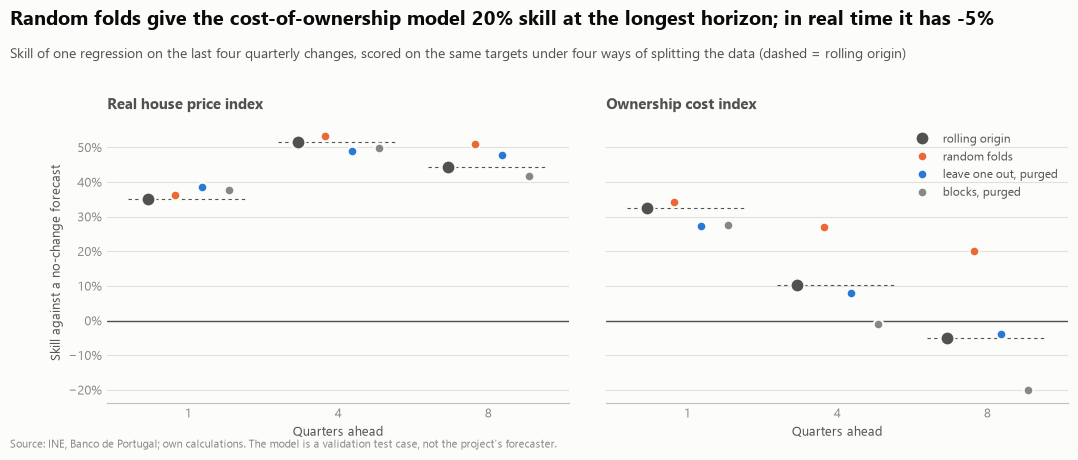

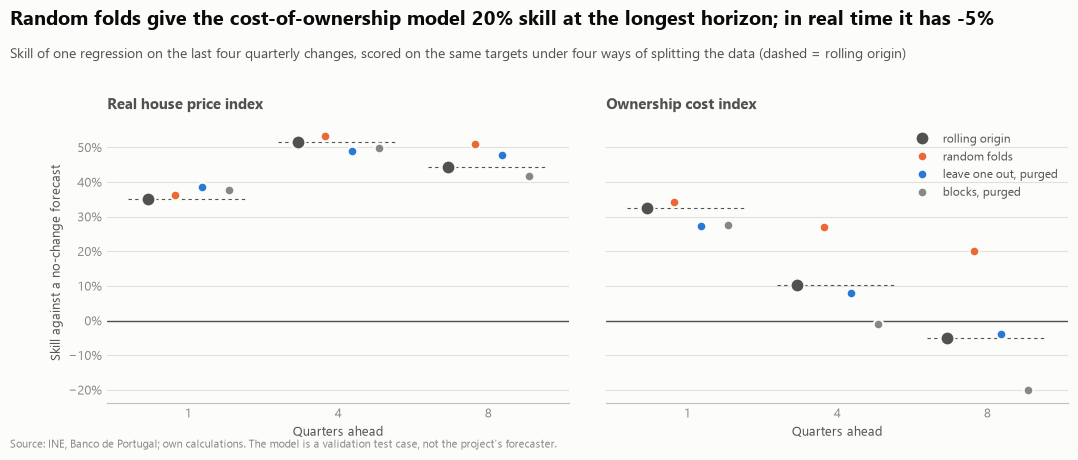

In [3]:
fig = charts.validation_schemes(
    [{"title": name, "scores": scores[scores["series"] == name]} for name in series]
)
style.save_fig(fig, "p4", "validation_schemes")
fig

## Step 2 — Is the gap leakage or the future?
The purged schemes still use future observations but drop overlapping windows. If they land near the rolling
origin, the gap is leakage from overlapping windows; if not, using the future is what flatters.

In [4]:
gap = (
    scores[scores["scheme"] != "rolling origin"]
    .pivot_table(index=["series", "h"], columns="scheme", values="skill_vs_rolling")[
        ["random folds", "leave one out, purged", "blocks, purged"]
    ]
    .mul(100)
    .round(1)
)
print("Skill minus rolling-origin skill, percentage points")
gap

Skill minus rolling-origin skill, percentage points


scheme                    random folds  leave one out, purged  blocks, purged
series                 h                                                     
Ownership cost index   1           1.9                   -5.2            -4.8
                       4          16.9                   -2.3           -11.1
                       8          25.1                    1.0           -15.2
Real house price index 1           0.9                    3.5             2.3
                       4           1.7                   -2.6            -1.7
                       8           6.7                    3.5            -2.4

## Step 3 — Does the verdict on the model change?
A validation scheme matters if it changes a decision. Here: does the model beat a no-change forecast?

In [5]:
verdict = scores.assign(beats_naive=scores["skill"] > 0).pivot_table(
    index=["series", "h"], columns="scheme", values="beats_naive", aggfunc="first"
)[fc.SCHEMES]
style.save_table(verdict.reset_index(), "p4", "validation_verdicts")
verdict

scheme                    rolling origin  random folds  leave one out, purged  \
series                 h                                                        
Ownership cost index   1            True          True                   True   
                       4            True          True                   True   
                       8           False          True                  False   
Real house price index 1            True          True                   True   
                       4            True          True                   True   
                       8            True          True                   True   

scheme                    blocks, purged  
series                 h                  
Ownership cost index   1            True  
                       4           False  
                       8           False  
Real house price index 1            True  
                       4            True  
                       8            True

## What this says
See `reports/p4_forecast.md` (validation schemes). Table: `reports/tables/p4/validation_schemes.csv`.